# ICS 635 · Final Project
## Clean-Energy Momentum Forecast

**Team:** Jiyeon Chun, Kylie Higashionna, Matt Ong

We want to forecast each U.S. state's renewable share of electricity generation one month
ahead, and determine which historical generation and seasonal features matter most for making
accurate predictions. We will compare different machine learning and time-series models to see
whether they can outperform a simple seasonal baseline.

- **Data:** EIA Open Data, Electric Power Operations (monthly), "Utility Scale Electricity Net Generation", from EIA's bulk file
- **Target:** renewable generation (REN = AOR + HYC) / total generation (ALL), all sectors (sector ID 99)
- **Unit of analysis:** one row per state-month, 50 states, one global model

## Setup

This notebook uses Python 3.13. The next cell installs the packages listed in `requirements.txt`
into the active kernel. If it changes any installed package, restart the kernel before continuing.
If you create your environment with `uv`, use `uv venv --seed` so that it includes `pip`.

### Data

The notebook reads one file, `data/eia_generation_monthly_raw.csv`, which is included in this
repository. It was built from EIA's bulk electricity file, which needs no API key:

- **Source:** https://www.eia.gov/opendata/bulk/ELEC.zip, listed on https://www.eia.gov/opendata/bulk.php
- **Version used:** last modified by EIA on 2026-10-23
- **SHA-256 of `ELEC.zip`:** `73e289b5e23c28922f1c47686282f00e1459abee0376242862f17bfc2ada1f6b`

To rebuild the CSV from EIA yourself, run this from the repository folder:

```
python download_eia_data.py
```

It downloads `ELEC.zip` (about 300 MB) into `data/`, prints the file's date and SHA-256, and writes
the CSV. If you already downloaded `ELEC.zip` in a browser, run
`python download_eia_data.py --zip path/to/ELEC.zip` instead.

EIA updates the bulk file about once a month. If the SHA-256 printed by the script differs from the
one above, your download is a newer version and may include later months or revised values.

In [1]:
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [11]:
# --- Imports ---
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBRegressor

# --- Paths ---
DATA_DIR = Path("data")
RAW_PATH = DATA_DIR / "eia_generation_monthly_raw.csv"    # built from EIA's bulk file, sector 99
PANEL_PATH = DATA_DIR / "state_month_panel.csv"           # written by this notebook

# --- Reproducibility ---
SEED = 635
np.random.seed(SEED)

pd.set_option("display.max_columns", None)

## 1. Data Preprocessing

This section starts from the data as EIA publishes it and shows every change we make to it:
one row per location, fuel, and month becomes one row per state-month with a renewable share.

### 1.1 Load and inspect the raw data

All of our data comes from `eia_generation_monthly_raw.csv`, which `download_eia_data.py` builds from
the [EIA bulk file](https://www.eia.gov/opendata/bulk/ELEC.zip). It keeps EIA's monthly net generation
series for all sectors (sector 99) from 2001 onward, using the same column names as EIA's API.

In [12]:
raw = pd.read_csv(RAW_PATH, dtype={"sectorid": str})

# --- Size, coverage, and missing values ---
display(pd.Series({
    "rows": len(raw),
    "columns": raw.shape[1],
    "first month": raw["period"].min(),
    "last month": raw["period"].max(),
    "locations": raw["location"].nunique(),
    "fuel codes": raw["fueltypeid"].nunique(),
    "sectors": raw["sectorid"].nunique(),
    "blank generation values": int(raw["generation"].isna().sum()),
    "duplicate location-fuel-months": int(raw.duplicated(["location", "fueltypeid", "period"]).sum()),
}, name="Raw EIA data").to_frame())

display(raw.head())

# --- Column types and meaning ---
column_info = {
    "period":              ("identifier", "YYYY-MM",          "year and month"),
    "location":            ("categorical", "code",            "state, census region, or US total"),
    "stateDescription":    ("text", "none",                   "location name"),
    "sectorid":            ("categorical", "code",            "producer category; 99 = all sectors"),
    "sectorDescription":   ("text", "none",                   "sector name"),
    "fueltypeid":          ("categorical", "code",            "energy source, including aggregates such as ALL"),
    "fuelTypeDescription": ("text", "none",                   "fuel name"),
    "generation":          ("numeric", "thousand MWh",        "net generation; blank = no value published"),
    "generation-units":    ("text", "none",                   "unit label"),
}
display(pd.DataFrame(column_info, index=["type", "unit", "meaning"]).T)

# --- Fuel codes in the raw file ---
(raw.groupby(["fueltypeid", "fuelTypeDescription"])
    .agg(rows=("generation", "size"), blanks=("generation", lambda s: s.isna().sum()),
         first_month=("period", "min"))
    .reset_index())

,Raw EIA data
rows,261961
columns,9
first month,2001-01
last month,2026-08
locations,62
fuel codes,20
sectors,1
blank generation values,957
duplicate location-fuel-months,0


,period,location,stateDescription,sectorid,sectorDescription,fueltypeid,fuelTypeDescription,generation,generation-units
0,2026-08,US,United States,99,All Sectors,SUN,all utility-scale solar,38818.73419,thousand megawatthours
1,2026-07,US,United States,99,All Sectors,SUN,all utility-scale solar,41043.99639,thousand megawatthours
2,2026-06,US,United States,99,All Sectors,SUN,all utility-scale solar,38526.99908,thousand megawatthours
3,2026-05,US,United States,99,All Sectors,SUN,all utility-scale solar,36368.64302,thousand megawatthours
4,2026-04,US,United States,99,All Sectors,SUN,all utility-scale solar,30986.14115,thousand megawatthours


,type,unit,meaning
period,identifier,YYYY-MM,year and month
location,categorical,code,"state, census region, or US total"
stateDescription,text,none,location name
sectorid,categorical,code,producer category; 99 = all sectors
sectorDescription,text,none,sector name
fueltypeid,categorical,code,"energy source, including aggregates such as ALL"
fuelTypeDescription,text,none,fuel name
generation,numeric,thousand MWh,net generation; blank = no value published
generation-units,text,none,unit label


,fueltypeid,fuelTypeDescription,rows,blanks,first_month
0,ALL,all fuels,19096,0,2001-01
1,AOR,other renewables (total),18853,2,2001-01
2,COW,coal,18059,2,2001-01
3,DPV,small-scale solar photovoltaic,9400,165,2014-01
4,GEO,geothermal,3007,3,2001-01
5,HPS,hydro-electric pumped storage,8624,0,2001-01
6,HYC,conventional hydroelectric,18172,60,2001-01
7,NG,natural gas,18668,19,2001-01
8,NUC,nuclear,12332,0,2001-01
9,OOG,other gases,11110,11,2001-01


### Analysis

**Raw data.** The generation file has 261,961 rows across 62 locations, 20 fuel codes, and
2001-01 to 2026-08, with no duplicates and 957 blank values.

**There is no `REN` series, so we compute it.** The bulk file has no total-renewables (`REN`) code.
EIA's renewables total is conventional hydroelectric (`HYC`) plus "other renewables (total)" (`AOR`:
wind, utility-scale solar, geothermal, and biomass), so we use `REN = AOR + HYC`. Neither part works on
its own: for California in July 2013, `AOR` is 3,422 thousand MWh, while `AOR + HYC` is 6,615. Both
parts go back to 2001, so this also gives us `REN` for 2001-2002. EIA's API only has `REN` from 2003-01.

We checked this formula once against the `REN` values from EIA's API, which needs a key, so it is not
part of this notebook. For the 4,487 state-months where both values exist, 4,439 agree within
0.01 thousand MWh. The largest gap is 4.5 thousand MWh (Arizona, July 2003), which is 0.07 percentage
points of that state's renewable share.

**Missing values are not all the same.** A month with *no row* means EIA has no series for that fuel
yet, as with Delaware's renewables before 2006. A row with a *blank value* means a series exists but
nothing was published for that month. Section 1.2 treats these differently.

### 1.2 Transform the raw data into the state-month table

| Step | Change | Why |
|---|---|---|
| 1 | Keep the 50 states | Drops DC, census regions, and the US total, which would double count states |
| 2 | Keep sector 99 | REN and ALL must cover the same producers |
| 3 | Keep the fuels we use | The rest are subsets or are not used as features |
| 4 | Keep months through 2026-07 | The proposal's test period ends there |
| 5 | Pivot to one row per state-month | Models need one row per example |
| 6 | Add `REN = AOR + HYC` | The bulk file has no `REN` series |
| 7 | Compute `renewable_share` | The prediction target |

In [13]:
STATES = ("AL AK AZ AR CA CO CT DE FL GA HI ID IL IN IA KS KY LA ME MD MA MI MN MS MO "
          "MT NE NV NH NJ NM NY NC ND OH OK OR PA RI SC SD TN TX UT VT VA WA WV WI WY").split()
assert len(STATES) == 50

FUELS = ["ALL", "AOR", "HYC", "WND", "SUN", "COW", "NG", "NUC"]
LAST_MONTH = pd.Timestamp("2026-07-01")

# Row count after each step, so every change to the data is visible
steps = [("Raw EIA file", len(raw), "one row per location, fuel, and month")]

# --- Steps 1-4: filter the rows ---
rows = raw[raw["location"].isin(STATES)]
steps.append(("1. Keep the 50 states", len(rows), "drops DC, census regions, and US"))

rows = rows[rows["sectorid"] == "99"]
steps.append(("2. Keep sector 99", len(rows), "same producers in REN and ALL"))

rows = rows[rows["fueltypeid"].isin(FUELS)]
steps.append(("3. Keep the fuels we use", len(rows), ", ".join(FUELS)))

rows = rows.assign(date=pd.to_datetime(rows["period"], format="%Y-%m"))
rows = rows[rows["date"] <= LAST_MONTH]
steps.append(("4. Keep months through 2026-07", len(rows), "end of the proposal's test period"))

# --- Step 5: pivot to one row per state-month ---
all_months = pd.date_range("2001-01-01", LAST_MONTH, freq="MS")
full_index = pd.MultiIndex.from_product([STATES, all_months], names=["location", "date"])
keys = dict(index=["location", "date"], columns="fueltypeid")

# No row = no series yet, so generation is 0. Blank value = not published, so it stays missing.
wide = rows.pivot(values="generation", **keys).reindex(index=full_index, columns=FUELS)
is_blank = (rows.assign(blank=rows["generation"].isna())
            .pivot(values="blank", **keys)
            .reindex(index=full_index, columns=FUELS)
            .eq(True))
wide = wide.fillna(0).mask(is_blank)
steps.append(("5. Pivot to one row per state-month", len(wide), "50 states x 307 months"))

assert len(wide) == 50 * 307
assert wide["ALL"].notna().all() and (wide["ALL"] > 0).all()
wide.head()

fueltypeid                 ALL        AOR       HYC  WND  SUN       COW  \
location date                                                             
AL       2001-01-01  11326.642  401.16759   727.118  0.0  0.0  6557.913   
         2001-02-01   9576.039  331.77037   922.210  0.0  0.0  5479.455   
         2001-03-01   9364.445  355.48069  1299.668  0.0  0.0  5392.921   
         2001-04-01   7714.348  346.60869   696.398  0.0  0.0  4619.950   
         2001-05-01  10048.668  306.45667   394.587  0.0  0.0  5985.862   

fueltypeid                NG       NUC  
location date                           
AL       2001-01-01  566.478  2940.300  
         2001-02-01  276.610  2515.933  
         2001-03-01  389.456  1873.313  
         2001-04-01  491.732  1459.636  
         2001-05-01  640.437  2677.375

In [14]:
# --- Step 6: add REN = AOR + HYC (the bulk file has no REN series) ---
panel = wide.copy()
panel["REN"] = panel["AOR"] + panel["HYC"]   # stays missing if either part is blank
steps.append(("6. Add REN = AOR + HYC", len(panel), "bulk file has no REN series"))

print(f"REN is missing for {panel['REN'].isna().sum()} state-months because AOR or HYC is blank")

# --- Step 7: the target ---
panel["share_unclipped"] = panel["REN"] / panel["ALL"]
print("Shares above 1:")
display(panel.loc[panel["share_unclipped"] > 1, ["REN", "ALL", "share_unclipped"]])

panel["renewable_share"] = panel["share_unclipped"].clip(upper=1)
steps.append(("7. Compute renewable_share", len(panel), "REN / ALL, capped at 1"))

# Fuel mix: each fuel as a share of the state's generation. Used for lag features in Section 1.3.
for name, fuel in {"coal": "COW", "gas": "NG", "nuclear": "NUC", "hydro": "HYC",
                   "wind": "WND", "solar": "SUN"}.items():
    panel[f"{name}_share"] = panel[fuel] / panel["ALL"]
panel["other_ren_share"] = (panel["AOR"] - panel["WND"] - panel["SUN"]) / panel["ALL"]

panel = panel.reset_index()

# --- Every step in one table ---
pd.DataFrame(steps, columns=["step", "rows", "note"]).set_index("step")

REN is missing for 57 state-months because AOR or HYC is blank
Shares above 1:


fueltypeid                 REN        ALL  share_unclipped
location date                                             
VT       2019-05-01  239.47910  239.47089         1.000034
         2019-09-01  114.11276  113.99873         1.001000
         2019-11-01  167.33872  167.29958         1.000234
         2020-07-01  157.02748  156.58850         1.002803
         2020-08-01  120.19553  120.10341         1.000767
         2020-09-01   84.34279   84.18422         1.001884
         2020-10-01  169.42709  169.20641         1.001304
         2020-11-01  174.00472  173.87403         1.000752
         2025-05-01  252.35800  252.34744         1.000042

,rows,note
step,,
Raw EIA file,261961,"one row per location, fuel, and month"
1. Keep the 50 states,203695,"drops DC, census regions, and US"
2. Keep sector 99,203695,same producers in REN and ALL
3. Keep the fuels we use,103612,"ALL, AOR, HYC, WND, SUN, COW, NG, NUC"
4. Keep months through 2026-07,103249,end of the proposal's test period
5. Pivot to one row per state-month,15350,50 states x 307 months
6. Add REN = AOR + HYC,15350,bulk file has no REN series
7. Compute renewable_share,15350,"REN / ALL, capped at 1"


In [15]:
# --- One worked example: Hawaii, July 2024 ---
print("Before: rows in the raw EIA file")
display(raw.loc[(raw["location"] == "HI") & (raw["period"] == "2024-07") & raw["fueltypeid"].isin(FUELS),
                ["period", "location", "sectorid", "fueltypeid", "fuelTypeDescription", "generation"]])

print("After: one row in our table")
panel.loc[(panel["location"] == "HI") & (panel["date"] == "2024-07-01"),
          ["location", "date", "ALL", "AOR", "HYC", "REN", "renewable_share"]]

Before: rows in the raw EIA file


,period,location,sectorid,fueltypeid,fuelTypeDescription,generation
11122,2024-07,HI,99,SUN,all utility-scale solar,73.16162
36955,2024-07,HI,99,AOR,other renewables (total),185.48170
120170,2024-07,HI,99,HYC,conventional hydroelectric,7.98900
133847,2024-07,HI,99,WND,wind,68.38562
234256,2024-07,HI,99,ALL,all fuels,795.82150


After: one row in our table


fueltypeid,location,date,ALL,AOR,HYC,REN,renewable_share
3352,HI,2024-07-01,795.8215,185.4817,7.989,193.4707,0.243108


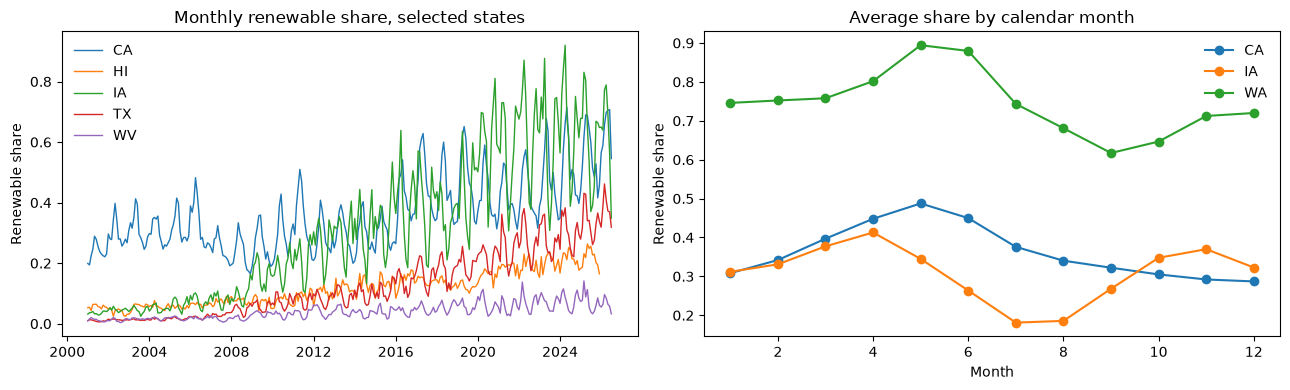

,mean,min,max
location,,,
DE,0.022,0.000,0.128
OH,0.022,0.003,0.134
NJ,0.023,0.011,0.057
MS,0.031,0.017,0.099
PA,0.033,0.012,0.069
FL,0.035,0.015,0.140
CT,0.036,0.018,0.093
LA,0.038,0.020,0.071
WV,0.040,0.004,0.141


In [16]:
# --- What the target looks like ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for state in ["CA", "HI", "IA", "TX", "WV"]:
    series = panel[panel["location"] == state]
    axes[0].plot(series["date"], series["renewable_share"], label=state, linewidth=1)
axes[0].set(title="Monthly renewable share, selected states", ylabel="Renewable share")
axes[0].legend(frameon=False)

by_month = (panel[panel["location"].isin(["CA", "IA", "WA"])]
            .groupby(["location", panel["date"].dt.month])["renewable_share"].mean().unstack(0))
by_month.plot(ax=axes[1], marker="o")
axes[1].set(title="Average share by calendar month", xlabel="Month", ylabel="Renewable share")
axes[1].legend(frameon=False, title=None)

plt.tight_layout()
plt.show()

panel.groupby("location")["renewable_share"].agg(["mean", "min", "max"]).sort_values("mean").round(3)

### 1.3 Features and data splits

Each row predicts one state's renewable share for one month, month *t*. Every feature uses only data
up to the end of month *t − 1*, so nothing from the month being predicted, or later, enters a feature.

| Group | Feature | Definition |
|---|---|---|
| State | `location` | State code, so one global model can learn state-level differences |
| History | `share_lag1`, `share_lag2`, `share_lag3` | Renewable share 1, 2, and 3 months earlier |
| History | `share_lag12` | Share in the same month one year earlier. This is also the seasonal naive baseline |
| History | `share_change_12m` | `share_lag1` minus the share 13 months earlier: the trend over the past year |
| History | `share_mean_3m`, `share_mean_12m` | Average share over the previous 3 and 12 months |
| History | `<fuel>_share_lag1` | Last month's share of coal, gas, nuclear, hydro, wind, solar, and other renewables |
| History | `log_total_gen_lag1` | Log of last month's total generation, a measure of the state's size |
| Seasonal | `month` | Calendar month of the month being predicted |

The ablation study compares models trained on **state + history** with models trained on
**state + history + seasonal**. `share_lag12` counts as history because it is a past value of the
target, even though it also carries some seasonal information.

The splits use the same date boundaries for every state, as in the proposal:

| Split | Months | State-months |
|---|---|---|
| Train | 2002-01 to 2018-12 | 10,200 |
| Validation | 2019-01 to 2022-12 | 2,400 |
| Test | 2023-01 to 2026-07 (2026 values are preliminary) | 2,150 |

2001 is not in any split. It only supplies the lag values for the first training months.

In [17]:
# --- Features: each one is known by the end of the month before the one we predict ---
df = panel.sort_values(["location", "date"]).reset_index(drop=True)
df.columns.name = None
assert (df.groupby("location").size() == len(all_months)).all()   # no gaps, so shift(k) = k months earlier

by_state = df.groupby("location")
FUEL_SHARES = ["coal_share", "gas_share", "nuclear_share", "hydro_share",
               "wind_share", "solar_share", "other_ren_share"]

for k in (1, 2, 3, 12):
    df[f"share_lag{k}"] = by_state["renewable_share"].shift(k)
df["share_change_12m"] = df["share_lag1"] - by_state["renewable_share"].shift(13)
for window in (3, 12):
    df[f"share_mean_{window}m"] = by_state["renewable_share"].transform(
        lambda s: s.shift(1).rolling(window, min_periods=1).mean())
for col in FUEL_SHARES:
    df[f"{col}_lag1"] = by_state[col].shift(1)
df["log_total_gen_lag1"] = np.log1p(by_state["ALL"].shift(1))
df["month"] = df["date"].dt.month

STATE_FEATURES = ["location"]
HISTORY_FEATURES = (["share_lag1", "share_lag2", "share_lag3", "share_lag12", "share_change_12m",
                     "share_mean_3m", "share_mean_12m", "log_total_gen_lag1"]
                    + [f"{c}_lag1" for c in FUEL_SHARES])
SEASONAL_FEATURES = ["month"]
TARGET = "renewable_share"
BASELINE = "share_lag12"   # seasonal naive forecast: same month one year earlier

df[["location", "date", TARGET] + HISTORY_FEATURES + SEASONAL_FEATURES].head(14)

,location,date,renewable_share,share_lag1,share_lag2,share_lag3,share_lag12,share_change_12m,share_mean_3m,share_mean_12m,log_total_gen_lag1,coal_share_lag1,gas_share_lag1,nuclear_share_lag1,hydro_share_lag1,wind_share_lag1,solar_share_lag1,other_ren_share_lag1,month
0,AK,2001-01-01,0.177306,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
1,AK,2001-02-01,0.165123,0.177306,NaN,NaN,NaN,NaN,0.177306,0.177306,6.382061,0.079477,0.622764,0.0,0.177158,0.000147,0.0,0.000000,2
2,AK,2001-03-01,0.170195,0.165123,0.177306,NaN,NaN,NaN,0.171215,0.171215,6.304754,0.098973,0.611564,0.0,0.164988,0.000135,0.0,0.000000,3
3,AK,2001-04-01,0.173289,0.170195,0.165123,0.177306,NaN,NaN,0.170875,0.170875,6.376923,0.088432,0.585674,0.0,0.170057,0.000138,0.0,0.000000,4
4,AK,2001-05-01,0.175781,0.173289,0.170195,0.165123,NaN,NaN,0.169536,0.171478,6.193789,0.076919,0.593516,0.0,0.173144,0.000145,0.0,0.000000,5
5,AK,2001-06-01,0.242670,0.175781,0.173289,0.170195,NaN,NaN,0.173088,0.172339,6.185564,0.084562,0.584848,0.0,0.175639,0.000142,0.0,0.000000,6
6,AK,2001-07-01,0.217981,0.242670,0.175781,0.173289,NaN,NaN,0.197247,0.184061,6.192371,0.080760,0.557524,0.0,0.242527,0.000143,0.0,0.000000,7
7,AK,2001-08-01,0.210221,0.217981,0.242670,0.175781,NaN,NaN,0.212144,0.188906,6.318833,0.099439,0.567916,0.0,0.217847,0.000134,0.0,0.000000,8
8,AK,2001-09-01,0.241972,0.210221,0.217981,0.242670,NaN,NaN,0.223624,0.191571,6.376380,0.111015,0.564276,0.0,0.210097,0.000124,0.0,0.000000,9
9,AK,2001-10-01,0.232880,0.241972,0.210221,0.217981,NaN,NaN,0.223391,0.197171,6.463288,0.092023,0.554872,0.0,0.241837,0.000134,0.0,0.000000,10


In [18]:
# --- Splits: the same date boundaries for every state ---
SPLITS = {"train":      ("2002-01-01", "2018-12-01"),
          "validation": ("2019-01-01", "2022-12-01"),
          "test":       ("2023-01-01", "2026-07-01")}
df["split"] = None
for name, (start, end) in SPLITS.items():
    df.loc[df["date"].between(start, end), "split"] = name
assert df.loc[df["split"].isna(), "date"].dt.year.eq(2001).all()   # only 2001 is left out

# Rows without a target cannot be trained on or scored
model_rows = df[df["split"].notna() & df[TARGET].notna()].reset_index(drop=True)

display(df[df["split"].notna()]
        .groupby("split", sort=False)
        .agg(first_month=("date", "min"), last_month=("date", "max"), state_months=("date", "size"),
             target_missing=(TARGET, lambda s: s.isna().sum()))
        .assign(rows_used=model_rows.groupby("split").size()))

# Features can still be missing when an earlier month was blank. Section 2 fills them inside each
# model's pipeline, using values learned from the training split only.
print("Missing feature values in the rows we use:")
display(model_rows.groupby("split", sort=False)[HISTORY_FEATURES + SEASONAL_FEATURES]
        .agg(lambda s: s.isna().sum()).T.loc[lambda t: t.sum(axis=1) > 0])

,first_month,last_month,state_months,target_missing,rows_used
split,,,,,
train,2002-01-01,2018-12-01,10200,2,10198
validation,2019-01-01,2022-12-01,2400,0,2400
test,2023-01-01,2026-07-01,2150,55,2095


Missing feature values in the rows we use:


split,train,validation,test
share_lag1,2,0,7
share_lag2,2,0,7
share_lag3,2,0,2
share_lag12,2,0,0
share_change_12m,54,0,7
coal_share_lag1,1,0,0
gas_share_lag1,7,0,2
hydro_share_lag1,0,0,7
wind_share_lag1,4,1,2
solar_share_lag1,37,0,11


In [19]:
# --- Check: Hawaii, July 2024 (the proposal's example) uses only earlier months ---
hi = df.set_index(["location", "date"])
july_2024 = hi.loc[("HI", pd.Timestamp("2024-07-01"))]
assert july_2024["share_lag1"] == hi.loc[("HI", pd.Timestamp("2024-06-01")), TARGET]
assert july_2024["share_lag12"] == hi.loc[("HI", pd.Timestamp("2023-07-01")), TARGET]
display(july_2024[[TARGET, "share_lag1", "share_lag12", "share_mean_3m", "share_change_12m", "month"]]
        .to_frame("HI, 2024-07"))

# --- The baseline to beat, on validation only. The test split stays untouched until the end ---
val = model_rows[model_rows["split"] == "validation"]
assert val[BASELINE].notna().all()
print(f"Seasonal naive baseline on validation: "
      f"MAE {mean_absolute_error(val[TARGET], val[BASELINE]):.4f}, "
      f"RMSE {mean_squared_error(val[TARGET], val[BASELINE]) ** 0.5:.4f}")

,"HI, 2024-07"
renewable_share,0.243108
share_lag1,0.251062
share_lag12,0.2343
share_mean_3m,0.231172
share_change_12m,0.019474
month,7


Seasonal naive baseline on validation: MAE 0.0314, RMSE 0.0510


### Analysis

**The splits match the proposal.** Train, validation, and test have 10,200, 2,400, and 2,150
state-months.

**Rows without a target are dropped.** 55 of the 57 missing `REN` values fall in the test period, so
we score models on 2,095 of the 2,150 test state-months. Every model and the baseline are scored on
the same rows.

**Some features are missing.** When an earlier month was blank, its lag is missing too. The largest
gap is `share_change_12m` in training, missing for 54 rows: 50 of them are January 2002, which has no
value 13 months earlier. We leave these as missing here and fill them inside each model's pipeline in
Section 2.

**The baseline to beat.** On validation, the seasonal naive forecast is off by 0.031 on average (MAE),
or about 3 percentage points of renewable share. We do not score anything on the test split until the
final comparison.